In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"/Users/HP/Downloads/Indian Airlines.csv")


In [2]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [2]:
#How many records are in the dataset?
print("Total Record in Rows:",
         df.shape[0])
print("total record in columns:",
      df.shape[1])

Total Record in Rows: 300153
total record in columns: 12


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [4]:
#TOTAL AIRLINE AVAILABLE
print("no of airlines are available:",df['airline'].nunique())

no of airlines are available: 6


In [5]:
#different airline
print("no of airlines are available:",df['airline'].unique())

no of airlines are available: ['SpiceJet' 'AirAsia' 'Vistara' 'GO_FIRST' 'Indigo' 'Air_India']


In [6]:
#average ticket price
print("AVG ticket price:",df['price'].mean())

AVG ticket price: 20889.660523133203


In [7]:
#max ticket price
print("max ticket price:",df['price'].max())

max ticket price: 123071


In [8]:
#min ticket price
print("min ticket price:",df['price'].min())

min ticket price: 1105


In [9]:
#available cities
print("cities are available:",df['source_city'].unique())

cities are available: ['Delhi' 'Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai']


In [10]:
#avg flight duration 
print("AVG flight duration:",df['duration'].mean())

AVG flight duration: 12.221020812718846


In [12]:
#no of economy and business class sheet available
df['class'].value_counts()


class
Economy     206666
Business     93487
Name: count, dtype: int64

In [16]:
#highest airline count
df['airline'].value_counts().head(1)

airline
Vistara    127859
Name: count, dtype: int64

In [30]:
#Which airline has the highest average ticket price?
df.groupby('airline')['price'].mean().max()

30396.53630170735

In [31]:
#which airline has the lowest avg ticket price?
df.groupby('airline')['price'].mean().min()

4091.0727419555224

In [37]:
#which airline has highest max ticket price?
df.groupby('airline')['price'].max().tail(1)

airline
Vistara    123071
Name: price, dtype: int64

In [36]:
#sorting
df.groupby('airline')['price'].mean().sort_values(ascending=True).head(1)

airline
AirAsia    4091.072742
Name: price, dtype: float64

In [56]:
#which airline offers chepeast economy ticket price

df.groupby('airline')['class'].value_counts().sort_values(ascending=True).head(1)

airline   class  
SpiceJet  Economy    9011
Name: count, dtype: int64

In [74]:
#which airline offers chepeast business ticket price
df1=df.groupby('class').get_group('Business')
df1['price'].sort_values(ascending=True).head(1)


295771    12000
Name: price, dtype: int64

In [79]:
df.groupby('class').get_group('Business').min().head(1)


Unnamed: 0    206666
dtype: object

In [4]:
#which airline highest avg duration
df.groupby('airline')['duration'].mean().sort_values(ascending=False).head(1)

airline
Air_India    15.504235
Name: duration, dtype: float64

In [11]:
#highest city departing
df['source_city'].value_counts().head(1)

source_city
Delhi    61343
Name: count, dtype: int64

In [13]:
#Which city has the highest number of arriving flights?
df['destination_city'].value_counts().head(1)

destination_city
Mumbai    59097
Name: count, dtype: int64

In [7]:
#which city has highest avg ticket price
df.groupby('source_city')['price'].mean().sort_values(ascending=False).head(1)

source_city
Chennai    21995.339871
Name: price, dtype: float64

In [6]:
#Which source-destination route has the highest average ticket price?
df.groupby(['source_city','destination_city'])['price'].mean().sort_values(ascending=False).head(1)

source_city  destination_city
Chennai      Bangalore           25081.850454
Name: price, dtype: float64

In [5]:
#Which route has the cheapest average ticket price?
df.groupby(['source_city','destination_city'])['price'].mean().sort_values(ascending=False).tail(1)

source_city  destination_city
Hyderabad    Delhi               17243.945685
Name: price, dtype: float64

In [4]:
#Which city pair has the highest number of flights?
df.groupby(['source_city','destination_city']).size().sort_values(ascending=False).head(1)

source_city  destination_city
Delhi        Mumbai              15289
dtype: int64

In [3]:
#which city has highest avg flight duration
df.groupby('source_city')['duration'].mean().sort_values().head(1)

source_city
Delhi    11.515499
Name: duration, dtype: float64

In [9]:
#avg economy ticket price
print("The avg economy ticket price:",df.groupby('class').get_group('Economy')['price'].mean())

The avg economy ticket price: 6572.342383362527


In [11]:
#avg business ticket price
print("the avg Business ticket price:",df.groupby('class').get_group('Business')['price'].mean())

the avg Business ticket price: 52540.08112357868


In [13]:
#price diff between ecoonomy and business
Eco=df.groupby('class').get_group('Economy')['price'].mean()
Busi=df.groupby('class').get_group('Business')['price'].mean()
print("different between Economy and Business :",Busi-Eco)

different between Economy and Business : 45967.738740216155


In [14]:
#which class has greater ticket price
df.groupby('class')['price'].std().head(1)

class
Business    12969.314606
Name: price, dtype: float64

In [15]:
#departure time category gas the highest number of flights
df['departure_time'].value_counts().head(1)

departure_time
Morning    71146
Name: count, dtype: int64

In [16]:
#arrival time category has the highest number of flights
df['arrival_time'].value_counts().head(1)

arrival_time
Night    91538
Name: count, dtype: int64

In [17]:
#departure time has the highest avg ticket price
df.groupby('departure_time')['price'].mean().sort_values(ascending=False).head(1)

departure_time
Night    23062.146808
Name: price, dtype: float64

In [18]:
#arrival time has lowest avg ticket price
df.groupby('arrival_time')['price'].mean().sort_values(ascending=False).head(1)

arrival_time
Evening    23044.371615
Name: price, dtype: float64

In [19]:
#does departure time influence ticket prices
df.groupby('departure_time')['price'].mean().sort_values(ascending=False)

departure_time
Night            23062.146808
Morning          21630.760254
Evening          21232.361894
Early_Morning    20370.676718
Afternoon        18179.203331
Late_Night        9295.299387
Name: price, dtype: float64

In [20]:
#airline has the longest avg flight duration 
df.groupby('airline')['duration'].mean().sort_values(ascending=False).head(1)

airline
Air_India    15.504235
Name: duration, dtype: float64

In [21]:
#airlin has the shortest avg flight duration
df.groupby('airline')['duration'].mean().sort_values(ascending=False).tail(1)

airline
Indigo    5.795197
Name: duration, dtype: float64

In [22]:
#does flight duration after ticket prices
df.groupby('duration')['price'].mean().sort_values(ascending=False)

duration
32.00    55228.656250
34.33    49597.324324
35.08    40580.205128
30.25    38819.056604
40.67    36614.000000
             ...     
1.17      2632.209375
1.08      2589.311031
1.00      2266.063660
0.92      2003.538462
0.83      1973.557692
Name: price, Length: 476, dtype: float64

In [23]:
# g=false )routes have the longest flight duration
df.groupby(['source_city', 'destination_city'])['duration'].mean().sort_values(ascending=False)

source_city  destination_city
Kolkata      Chennai             14.774182
Chennai      Kolkata             14.515774
Bangalore    Chennai             14.480207
             Hyderabad           14.162433
Chennai      Bangalore           13.952594
Kolkata      Hyderabad           13.853108
             Bangalore           13.792947
Hyderabad    Kolkata             13.535322
             Chennai             13.293238
Mumbai       Hyderabad           13.263310
Chennai      Hyderabad           13.153985
Bangalore    Kolkata             13.099143
Kolkata      Mumbai              12.991933
Mumbai       Kolkata             12.836848
Delhi        Kolkata             12.735966
Mumbai       Chennai             12.665900
Delhi        Hyderabad           12.518350
             Chennai             12.433965
Chennai      Mumbai              12.374656
Hyderabad    Bangalore           12.093317
             Mumbai              11.962923
Mumbai       Bangalore           11.612023
Kolkata      Delhi      

In [24]:
# the relationship between flight duration and ticket price
df[['duration', 'price']].corr()

,duration,price
duration,1.000000,0.204222
price,0.204222,1.000000


In [25]:
#Does ticket price increase when departure dates approach
df.groupby('days_left')['price'].mean()

days_left
1     21591.867151
2     30211.299801
3     28976.083569
4     25730.905653
5     26679.773368
6     24856.493902
7     25588.367351
8     24895.883995
9     25726.246072
10    25572.819134
11    22990.656070
12    22505.803322
13    22498.885384
14    22678.002363
15    21952.540852
16    20503.546237
17    20386.353949
18    19987.445168
19    19507.677375
20    19699.983390
21    19430.494058
22    19590.667385
23    19840.913451
24    19803.908896
25    19571.641791
26    19238.290278
27    19950.866195
28    19534.986047
29    19744.653119
30    19567.580834
31    19392.706612
32    19258.135308
33    19306.271739
34    19562.008266
35    19255.652996
36    19517.688444
37    19506.306516
38    19734.912316
39    19262.095556
40    19144.972439
41    19347.440460
42    19154.261659
43    19340.528894
44    19049.080174
45    19199.876307
46    19305.351623
47    18553.272038
48    18998.126851
49    18992.971888
Name: price, dtype: float64

In [26]:
#the average ticket price when booked 1 day before departure
print(" average ticket price when booked 1 day before departure:",df[df['days_left'] == 1]['price'].mean())

 average ticket price when booked 1 day before departure: 21591.867151011935


In [27]:
#the average ticket price when booked 30 days before departure
print("average ticket price when booked 30 days before departure:",df[df['days_left'] == 30]['price'].mean())

average ticket price when booked 30 days before departure: 19567.58083371789


In [28]:
#the relationship between days left and ticket price
df[['days_left', 'price']].corr()

,days_left,price
days_left,1.000000,-0.091949
price,-0.091949,1.000000


In [29]:
#type of flight is most common: non-stop, one-stop or two-or-more stops
df['stops'].value_counts().head(1)

stops
one    250863
Name: count, dtype: int64

In [30]:
# is non-stop flights cost more than connecting flights
df.groupby('stops')['price'].mean()

stops
one            22900.992482
two_or_more    14113.450775
zero            9375.938535
Name: price, dtype: float64

In [31]:
#the average price for each stop category
df.groupby('stops')['price'].mean()

stops
one            22900.992482
two_or_more    14113.450775
zero            9375.938535
Name: price, dtype: float64

EDA

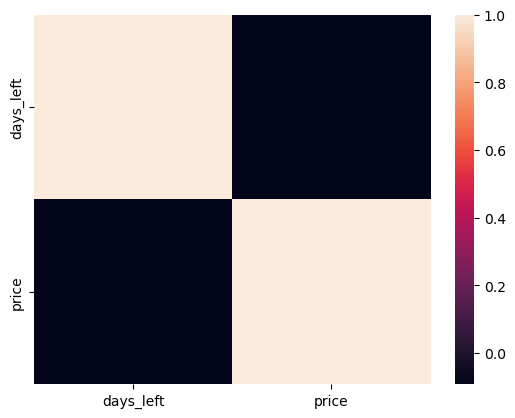

In [4]:
#corelation analysis
correlation = df[['duration', 'days_left', 'price']].corr()
sns.heatmap(df[['days_left', 'price']].corr())
plt.show()

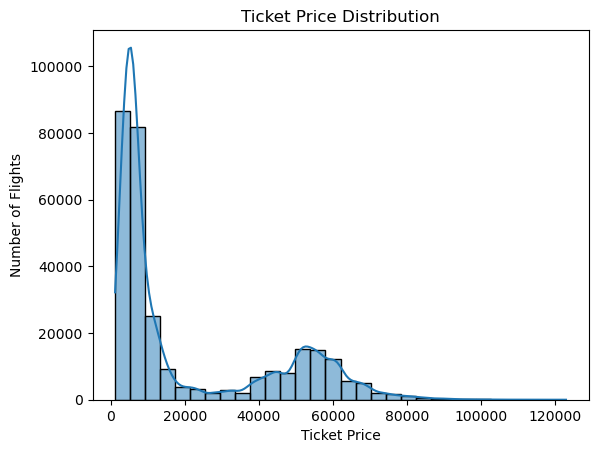

In [3]:
#Ticket Price Distribution
sns.histplot(df['price'], bins=30, kde=True)
plt.title('Ticket Price Distribution')
plt.xlabel('Ticket Price')
plt.ylabel('Number of Flights')
plt.show()

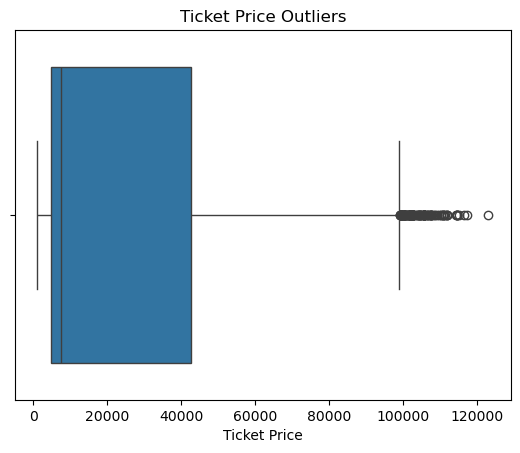

In [4]:
#dentify Ticket Price Outliers
sns.boxplot(x=df['price'])
plt.title('Ticket Price Outliers')
plt.xlabel('Ticket Price')
plt.show()

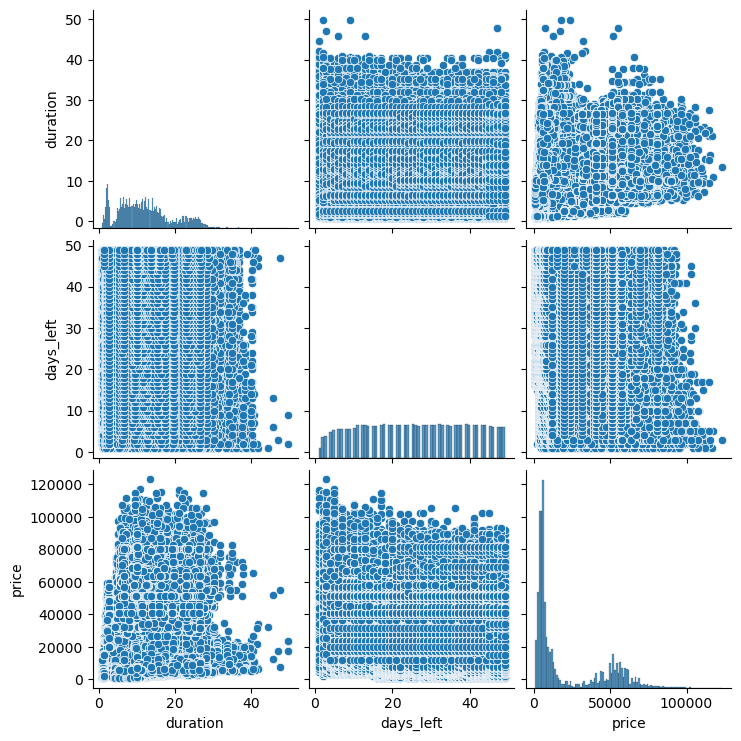

In [5]:
#Pair Plot Analysis
sns.pairplot(df[['duration', 'days_left', 'price']])
plt.show()

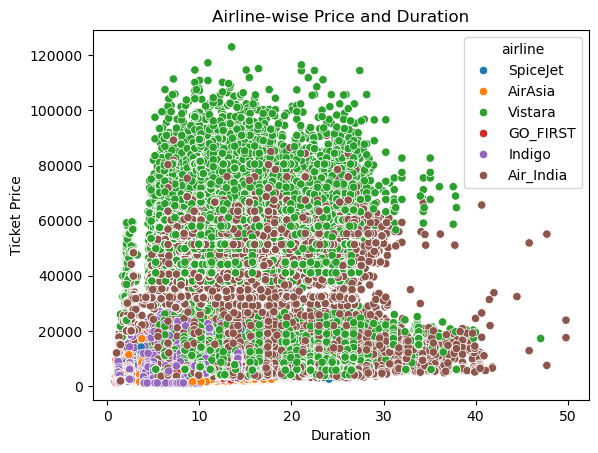

In [6]:
#Airline-wise Price and Duration Relationship
sns.scatterplot(data=df, x='duration', y='price', hue='airline')
plt.title('Airline-wise Price and Duration')
plt.xlabel('Duration')
plt.ylabel('Ticket Price')
plt.show()

#advance business intelligence queries

In [7]:
#airline has the highest# price variation
df.groupby('airline')['price'].std().sort_values(ascending=False).head(1)

airline
Vistara    25637.159445
Name: price, dtype: float64

In [8]:
#Does the number of stops influence fares
df.groupby('stops')['price'].mean().sort_values(ascending=False)

stops
one            22900.992482
two_or_more    14113.450775
zero            9375.938535
Name: price, dtype: float64

In [9]:
#airline has the highest-priced individual flight
df.groupby('airline')['price'].max().sort_values(ascending=False).head(1)

airline
Vistara    123071
Name: price, dtype: int64

In [11]:
#have the cheapest fares
df.groupby(['source_city', 'destination_city'])['price'].mean().sort_values().head(5)

source_city  destination_city
Hyderabad    Delhi               17243.945685
Delhi        Hyderabad           17347.288379
Bangalore    Delhi               17723.313972
Delhi        Bangalore           17880.216315
Mumbai       Delhi               18725.320008
Name: price, dtype: float64

In [12]:
#airlines have the most expensive Business tickets
df1=df.groupby('class').get_group('Business')
df1.groupby('airline')['price'].max()

airline
Air_India     90970
Vistara      123071
Name: price, dtype: int64

In [13]:
#How do booking days affect prices across airlines
df.groupby(['airline', 'days_left'])['price'].mean().reset_index().sort_values(['airline', 'days_left'])

,airline,days_left,price
0,AirAsia,1,10867.710843
1,AirAsia,2,9374.676923
2,AirAsia,3,8732.798507
3,AirAsia,4,7198.103896
4,AirAsia,5,8300.835821
...,...,...,...
289,Vistara,45,28734.082358
290,Vistara,46,29047.204097
291,Vistara,47,28405.029445
292,Vistara,48,28801.060450
